# Base de datos Proyeccion de Hogares
- Fuente: DANE

https://www.dane.gov.co/index.php/estadisticas-por-tema/demografia-y-poblacion/proyecciones-de-viviendas-y-hogares

Presentado por:
- Laura Marcela Ramirez Casallas
- Kevin Alejandro Caicedo Rodriguez
- Jhon Jairo Meneses Prieto
- Jeferson Andrés Gutiérrez Gutiérrez

## Descarga base y trasnformacion

In [4]:
import pandas as pd
import logging

logging.basicConfig(level=logging.INFO, format='%(levelname)s - %(message)s')

def cargar_proyeccion_hogares_dane(ruta_excel):

    logging.info("Iniciando extracción de proyecciones DANE...")

    try:
        df_raw = pd.read_excel(
            ruta_excel,
            sheet_name='Proyecciones Hogares mpio',
            header=None,
            skiprows=8,
            dtype=object
        )

        # Construir encabezados
        base, anios = df_raw.iloc[0], df_raw.iloc[1]

        columnas = [
            str(n).strip() if pd.notna(n) and str(n).strip()
            else str(int(float(a))) if pd.notna(a)
            else f'columna_{i}'
            for i, (n, a) in enumerate(zip(base, anios))
        ]

        df = df_raw.iloc[2:].copy()
        df.columns = columnas
        df = df.dropna(how='all').dropna(axis=1, how='all')

        # Validar columnas
        requeridas = [
            'Código Departamento', 'Nombre Departamento',
            'Código Municipio', 'Nombre Municipio', 'Área'
        ]

        faltantes = set(requeridas) - set(df.columns)
        if faltantes:
            raise ValueError(f"Columnas faltantes: {faltantes}")

        # Limpiar y normalizar datos
        df['Código Departamento'] = df['Código Departamento'].astype(str).str.strip().str.zfill(2)
        df['Código Municipio'] = df['Código Municipio'].astype(str).str.strip().str.zfill(5)
        df['Área'] = df['Área'].astype(str).str.strip().str.capitalize()

        # Filtrar cabeceras municipales
        df = df[df['Área'] == 'Cabecera'].copy()
        df.rename(columns={'Código Municipio': 'divipola'}, inplace=True)

        # Convertir años a valores numéricos
        columnas_anios = [c for c in df.columns if str(c).isdigit() and len(str(c)) == 4]
        df[columnas_anios] = df[columnas_anios].apply(pd.to_numeric, errors='coerce')

        logging.info(f"Extracción completada: {len(df)} registros urbanos.")
        logging.info(f"Años disponibles: {columnas_anios}")

        return df.reset_index(drop=True)

    except Exception as e:
        logging.error(f"Error procesando Excel: {e}")
        raise


# Ejecución
df_proy_hogar = cargar_proyeccion_hogares_dane(
    r'D:\JohnM\UAndes\Proyecto MIAD\proyecto_MIAD\Bases\proyecciones-hogares-dptal-mpal-2018-2042.xlsx'
)

display(df_proy_hogar.head())

INFO - Iniciando extracción de proyecciones DANE...


INFO - Extracción completada: 1123 registros urbanos.
INFO - Años disponibles: ['2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', '2027', '2028', '2029', '2030', '2031', '2032', '2033', '2034', '2035', '2036', '2037', '2038', '2039', '2040', '2041', '2042']


,Código Departamento,Nombre Departamento,divipola,Nombre Municipio,Área,Año de la proyección de hogares,2019,2020,2021,2022,...,2033,2034,2035,2036,2037,2038,2039,2040,2041,2042
0,05,Antioquia,05001,Medellín,Cabecera,798786,815403,833658,847054,857215,...,945147,950438,955307,959737,963708,967136,969999,972347,974101,975236
1,05,Antioquia,05002,Abejorral,Cabecera,2752,2849,2945,3018,3083,...,3672,3707,3747,3782,3816,3853,3879,3912,3942,3964
2,05,Antioquia,05004,Abriaquí,Cabecera,341,354,361,368,375,...,456,461,462,464,467,478,482,486,487,490
3,05,Antioquia,05021,Alejandría,Cabecera,897,940,977,1017,1049,...,1439,1482,1522,1557,1592,1638,1674,1712,1746,1786
4,05,Antioquia,05030,Amagá,Cabecera,4548,4712,4883,5029,5165,...,6591,6720,6843,6966,7086,7199,7318,7428,7541,7648


In [10]:
df_proy_hogar.rename(
    columns={'Año de la proyección de hogares': '2018'},
    inplace=True
)
# Revisar valores de 2018 que no se puedan convertir a número
valores_2018 = pd.to_numeric(df_proy_hogar["2018"], errors="coerce")

print("Valores no numéricos:", (valores_2018.isna() & df_proy_hogar["2018"].notna()).sum())

# Convertir a formato numérico
df_proy_hogar["2018"] = valores_2018
display(df_proy_hogar.head(5))

Valores no numéricos: 0


,Código Departamento,Nombre Departamento,divipola,Nombre Municipio,Área,2018,2019,2020,2021,2022,...,2033,2034,2035,2036,2037,2038,2039,2040,2041,2042
0,05,Antioquia,05001,Medellín,Cabecera,798786,815403,833658,847054,857215,...,945147,950438,955307,959737,963708,967136,969999,972347,974101,975236
1,05,Antioquia,05002,Abejorral,Cabecera,2752,2849,2945,3018,3083,...,3672,3707,3747,3782,3816,3853,3879,3912,3942,3964
2,05,Antioquia,05004,Abriaquí,Cabecera,341,354,361,368,375,...,456,461,462,464,467,478,482,486,487,490
3,05,Antioquia,05021,Alejandría,Cabecera,897,940,977,1017,1049,...,1439,1482,1522,1557,1592,1638,1674,1712,1746,1786
4,05,Antioquia,05030,Amagá,Cabecera,4548,4712,4883,5029,5165,...,6591,6720,6843,6966,7086,7199,7318,7428,7541,7648


## Calidad Datos

| Criterio | Validación | Importancia para el proyecto |
|---|---|---|
| **Totalidad** | Registros, variables, nulos y completitud. | Identificar información faltante en las proyecciones de hogares. |
| **Consistencia** | Duplicados exactos y llave municipio-área. | Evitar duplicidad de municipios y áreas geográficas. |
| **Claridad** | Nombres de columnas y variables. | Garantizar que las variables sean comprensibles e identificables. |
| **Formato** | Tipos de datos, DIVIPOLA, códigos departamentales y años. | Garantizar la integración con las demás fuentes mediante DIVIPOLA. |

In [11]:

def calidad_datos_hogares(df):
    # Identificar columnas de proyección (2018-2042)
    cols_anios = [c for c in df.columns if str(c).isdigit() and 2018 <= int(c) <= 2042]

    print("=== 1. TOTALIDAD ===")
    print(f"Registros: {len(df):,}")
    print(f"Variables: {len(df.columns)}")
    print("\nNulos por variable:")
    print(df.isnull().sum())
    print("\nCompletitud (%):")
    print(((1 - df.isnull().mean()) * 100).round(2))

    print("\n=== 2. CONSISTENCIA ===")
    print("Duplicados exactos:", df.duplicated().sum())
    print("Duplicados municipio-área:", df.duplicated(["divipola", "Área"]).sum())
    print("Códigos DIVIPOLA únicos:", df["divipola"].nunique())

    print("\n=== 3. CLARIDAD ===")
    print("Nombres de variables:", df.columns.tolist())
    print("Columnas sin nombre:", [c for c in df.columns if not str(c).strip()])
    print("Columnas duplicadas:", df.columns[df.columns.duplicated()].tolist())

    print("\n=== 4. FORMATO ===")
    print("Tipos de datos:")
    print(df.dtypes)
    print("\nColumnas de proyección:", len(cols_anios))
    print("Años disponibles:", sorted([int(c) for c in cols_anios]))

    # Validar códigos territoriales
    divipola = df["divipola"].astype("string").str.strip()
    print("\nDIVIPOLA inválidos:", (~divipola.str.fullmatch(r"\d{5}", na=False)).sum())

    depto = df["Código Departamento"].astype("string").str.strip()
    print("Códigos de departamento inválidos:", (~depto.str.fullmatch(r"\d{2}", na=False)).sum())

    # Validar nombres y espacios vacíos
    for col in ["Nombre Departamento", "Nombre Municipio", "Área"]:
        vacios = df[col].astype("string").str.strip().eq("").sum()
        print(f"Valores vacíos en {col}: {vacios}")

    # Validar consistencia territorial
    depto_divipola = divipola.str[:2]
    print("Inconsistencias departamento-DIVIPOLA:", (depto != depto_divipola).sum())

    # Validación del área geográfica
    print("\n=== VALIDACIÓN DE ÁREA ===")
    print("Áreas disponibles:", df["Área"].unique().tolist())
    print("Registros diferentes de Cabecera:", (df["Área"].str.strip() != "Cabecera").sum())

    # Validar proyecciones numéricas y rangos
    for col in cols_anios:
        valores = pd.to_numeric(df[col], errors="coerce")
        no_numericos = (valores.isna() & df[col].notna()).sum()
        negativos = (valores < 0).sum()
        if no_numericos > 0 or negativos > 0:
            print(f"{col}: No numéricos={no_numericos}, negativos={negativos}")

    print("\nValores negativos en proyecciones:",
          (df[cols_anios].apply(pd.to_numeric, errors="coerce") < 0).sum().sum())

    print("Duplicados por DIVIPOLA:", df.duplicated(["divipola"]).sum())

    return df[cols_anios].describe().T.round(2)

resumen_hogares = calidad_datos_hogares(df_proy_hogar)
display(resumen_hogares)


=== 1. TOTALIDAD ===
Registros: 1,123
Variables: 30

Nulos por variable:
Código Departamento    0
Nombre Departamento    0
divipola               0
Nombre Municipio       0
Área                   0
2018                   0
2019                   0
2020                   0
2021                   0
2022                   0
2023                   0
2024                   0
2025                   0
2026                   0
2027                   0
2028                   0
2029                   0
2030                   0
2031                   0
2032                   0
2033                   0
2034                   0
2035                   0
2036                   0
2037                   0
2038                   0
2039                   0
2040                   0
2041                   0
2042                   0
dtype: int64

Completitud (%):
Código Departamento    100.0
Nombre Departamento    100.0
divipola               100.0
Nombre Municipio       100.0
Área                   100.0
2

,count,mean,std,min,25%,50%,75%,max
2018,1123.0,10331.07,84370.52,0.0,665.0,1513.0,3861.5,2517859.0
2019,1123.0,10646.30,86797.90,0.0,680.0,1567.0,3980.0,2594051.0
2020,1123.0,10988.58,89602.85,0.0,689.5,1621.0,4135.0,2682879.0
2021,1123.0,11247.07,91478.06,0.0,698.5,1651.0,4240.0,2741313.0
2022,1123.0,11468.15,92944.05,0.0,713.5,1685.0,4359.0,2786833.0
2023,1123.0,11686.22,94370.33,0.0,727.5,1728.0,4473.0,2831177.0
2024,1123.0,11918.62,95864.11,0.0,759.5,1770.0,4584.5,2876859.0
2025,1123.0,12142.92,97264.23,0.0,753.5,1808.0,4682.5,2919627.0
2026,1123.0,12348.96,98463.14,0.0,778.5,1830.0,4784.5,2955986.0
2027,1123.0,12550.95,99600.84,0.0,798.0,1861.0,4863.0,2990257.0


Se ven municipios con hogares en cero en la proyeccion de todos los años, vamos a revisarlos

In [17]:
# Municipios con cero hogares en algún año
cols_anios = [str(a) for a in range(2018, 2043)]
display(df_proy_hogar.loc[
    (df_proy_hogar[cols_anios] == 0).any(axis=1),
    ["divipola", "Nombre Municipio", "Área"] + cols_anios
])

# Identificar municipios con valores cero en todos los años
df_proy_hogar["todos_cero"] = (df_proy_hogar[cols_anios] == 0).all(axis=1)

# Identificar primer año con proyección positiva
df_proy_hogar["primer_anio_positivo"] = df_proy_hogar[cols_anios].apply(
    lambda x: next((int(a) for a, v in x.items() if v > 0), None), axis=1
)

# Revisar registros
display(df_proy_hogar.loc[
    (df_proy_hogar[cols_anios] == 0).any(axis=1),
    ["divipola", "Nombre Municipio", "primer_anio_positivo", "todos_cero"]
])

,divipola,Nombre Municipio,Área,2018,2019,2020,2021,2022,2023,2024,...,2033,2034,2035,2036,2037,2038,2039,2040,2041,2042
595,27493,Nuevo Belén de Bajirá,Cabecera,0,0,0,0,0,0,3985,...,4763,4868,4961,5124,5212,5299,5383,5470,5552,5633
1090,91263,El Encanto (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1091,91405,La Chorrera (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1092,91407,La Pedrera (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1093,91430,La Victoria (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1094,91460,Miriti - Paraná (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1095,91530,Puerto Alegría (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1096,91536,Puerto Arica (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1098,91669,Puerto Santander (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1099,91798,Tarapacá (ANM),Cabecera,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,divipola,Nombre Municipio,primer_anio_positivo,todos_cero
595,27493,Nuevo Belén de Bajirá,2024.0,False
1090,91263,El Encanto (ANM),NaN,True
1091,91405,La Chorrera (ANM),NaN,True
1092,91407,La Pedrera (ANM),NaN,True
1093,91430,La Victoria (ANM),NaN,True
1094,91460,Miriti - Paraná (ANM),NaN,True
1095,91530,Puerto Alegría (ANM),NaN,True
1096,91536,Puerto Arica (ANM),NaN,True
1098,91669,Puerto Santander (ANM),NaN,True
1099,91798,Tarapacá (ANM),NaN,True


Consideraciones:

- Granularidad: la unidad de registro era municipio-área, Pero se decidio dejar solo informacion de cabecera municipal, permite enfocar el análisis en los territorios donde se concentra la dinámica urbana y donde, en principio, existe mayor pertinencia para evaluar oportunidades de vivienda urbana.
- Proyecciones: los años 2018–2042 son variables numéricas. Debemos verificar que todas tengan valores válidos y que no existan cifras negativas.
- Integración: DIVIPOLA debe conservarse como texto de cinco caracteres para cruzarlo con hurtos y las demás fuentes municipales.

Completitud: la fuente presenta completitud total en los registros evaluados. Se dispone de información para los 1.123 municipios durante los 25 años de proyección (2018–2042), Se identificaron proyecciones iguales a cero que requieren validación, pero no representan datos faltantes. 

Consistencia: No existen duplicados ni inconsistencias en los códigos DIVIPOLA. Cada registro corresponde a un territorio identificado para la categoría Cabecera. Se identificaron áreas no municipalizadas (ANM) que deberán excluirse según el alcance territorial del proyecto.. 

Claridad: la estructura de la información es comprensible y permite identificar las variables geográficas y temporales sin ambigüedades relevantes, las variables territoriales están identificadas y permite consultar sus proyecciones anuales. 

Formato: La estructura territorial presenta formatos adecuados (DIVIPOLA: texto de cinco dígitos, código de departamento: texto de dos dígitos, Nombres territoriales en texto y Años de proyección numéricas) 

### Conclusion: 

La evaluación de calidad de la base de proyecciones de hogares del DANE evidencia condiciones favorables para su utilización en el proyecto. Se identificaron 1.123 registros y 30 variables, con una completitud del 100 % y sin presencia de duplicados exactos ni duplicados en la llave territorial DIVIPOLA.

En términos de claridad, las variables presentan nombres identificables y una estructura organizada que diferencia la información geográfica de las proyecciones anuales. Respecto a la consistencia, se verificó que cada municipio cuenta con un único registro correspondiente a la categoría Cabecera y que no existen inconsistencias entre los códigos departamentales y los códigos DIVIPOLA.

En general, la fuente presenta condiciones adecuadas de calidad para continuar con las etapas de limpieza y entendimiento. Su estructura territorial y temporal permite analizar la evolución proyectada de los hogares en las cabeceras municipales y facilita su integración con las demás fuentes del proyecto mediante el código DIVIPOLA.

## Limpieza de datos

Consideraciones:
- Tenemos una estructura de datos por municipio y años en columnas. Por eso, las técnicas deben responder a las particularidades de las proyecciones de hogares.

| Técnica | Decisión | Justificación |
|---|---|---|
| **Eliminación general** | No aplicar | No existen registros nulos ni duplicados que justifiquen eliminar información. |
| **Eliminación de duplicados** | No aplicar | No se identificaron duplicados por DIVIPOLA. |
| **Imputación estadística** | No aplicar | No existen valores nulos y no debemos inventar proyecciones de hogares. |
| **Imputación aleatoria** | No aplicar | Generaría cifras artificiales sin fundamento demográfico. |
| **Estandarización territorial** | Aplicar | Garantizar códigos DIVIPOLA de cinco dígitos para integrar las fuentes. |
| **Validación de rangos** | Aplicar | Verificar que las proyecciones no tengan valores negativos. |
| **Tratamiento de valores extremos** | No eliminar | Las diferencias entre municipios son esperables por su tamaño poblacional y concentración urbana. |
| **Tratamiento de valores cero** | Validar, no eliminar automáticamente | Pueden representar ausencia de proyección o particularidades territoriales. |
| **Filtrado territorial** | Aplicar | Conservar municipios que cumplan las categorías definidas por el proyecto según Ley 617 de 2000. |
| **Filtrado geográfico** | Aplicar | Mantener exclusivamente la categoría Cabecera municipal. |

In [ ]:
# Estandarizar DIVIPOLA
df_proy_hogar["divipola"] = df_proy_hogar["divipola"].astype(str).str.strip()

# Estandarizar códigos departamentales
df_proy_hogar["Código Departamento"] = df_proy_hogar["Código Departamento"].astype(str).str.strip()

# Convertir proyecciones a formato numérico
cols_anios = [str(a) for a in range(2018, 2043)]
df_proy_hogar[cols_anios] = df_proy_hogar[cols_anios].apply(pd.to_numeric, errors="coerce")

# Verificar resultados
print("Nulos en proyecciones:", df_proy_hogar[cols_anios].isnull().sum().sum())
print("Valores negativos:", (df_proy_hogar[cols_anios] < 0).sum().sum())
print("DIVIPOLA inválidos:", (~df_proy_hogar["divipola"].str.fullmatch(r"\d{5}", na=False)).sum())
#granualridad
print("Áreas:", df_proy_hogar["Área"].unique().tolist())
print("Duplicados DIVIPOLA:", df_proy_hogar.duplicated("divipola").sum())
print("Municipios:", df_proy_hogar["divipola"].nunique())

Nulos en proyecciones: 0
Valores negativos: 0
DIVIPOLA inválidos: 0
Áreas: ['Cabecera']
Duplicados DIVIPOLA: 0
Municipios: 1123


In [20]:
#  Validación de valores extremos (Outliers)
display(df_proy_hogar[cols_anios].describe().round(2))

,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,...,2033,2034,2035,2036,2037,2038,2039,2040,2041,2042
count,1123.00,1123.0,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,...,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00,1123.00
mean,10331.07,10646.3,10988.58,11247.07,11468.15,11686.22,11918.62,12142.92,12348.96,12550.95,...,13685.07,13861.02,14032.85,14200.32,14363.38,14520.76,14671.83,14817.86,14957.32,15090.28
std,84370.52,86797.9,89602.85,91478.06,92944.05,94370.33,95864.11,97264.23,98463.14,99600.84,...,105173.35,105936.24,106658.74,107338.89,107973.60,108551.11,109062.27,109522.58,109921.68,110261.63
min,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,665.00,680.0,689.50,698.50,713.50,727.50,759.50,753.50,778.50,798.00,...,865.00,870.00,881.00,890.50,902.50,914.50,919.50,927.50,934.00,945.50
50%,1513.00,1567.0,1621.00,1651.00,1685.00,1728.00,1770.00,1808.00,1830.00,1861.00,...,2001.00,2032.00,2052.00,2070.00,2089.00,2100.00,2124.00,2142.00,2158.00,2190.00
75%,3861.50,3980.0,4135.00,4240.00,4359.00,4473.00,4584.50,4682.50,4784.50,4863.00,...,5444.00,5529.00,5619.00,5707.50,5774.50,5864.00,5952.50,6046.00,6133.00,6219.00
max,2517859.00,2594051.0,2682879.00,2741313.00,2786833.00,2831177.00,2876859.00,2919627.00,2955986.00,2990257.00,...,3152075.00,3173315.00,3193191.00,3211624.00,3228521.00,3243510.00,3256265.00,3267317.00,3276358.00,3283476.00


## entendimiento de los datos

In [23]:
# Preparar copia para EDA
df_hogares_eda = df_proy_hogar.copy()

# Convertir años a formato largo para graficas
df_hogares_eda = df_hogares_eda.melt(
    id_vars=["divipola", "Nombre Municipio", "Área"],
    value_vars=cols_anios,
    var_name="anio",
    value_name="hogares"
)

df_hogares_eda["anio"] = df_hogares_eda["anio"].astype(int)

print("Dimensiones:", df_hogares_eda.shape)
display(df_hogares_eda.head())

Dimensiones: (28075, 5)


,divipola,Nombre Municipio,Área,anio,hogares
0,05001,Medellín,Cabecera,2018,798786
1,05002,Abejorral,Cabecera,2018,2752
2,05004,Abriaquí,Cabecera,2018,341
3,05021,Alejandría,Cabecera,2018,897
4,05030,Amagá,Cabecera,2018,4548


,count,mean,std,min,25%,50%,75%,max
anio,,,,,,,,
2018,1123.0,10331.07,84370.52,0.0,665.0,1513.0,3861.5,2517859.0
2019,1123.0,10646.30,86797.90,0.0,680.0,1567.0,3980.0,2594051.0
2020,1123.0,10988.58,89602.85,0.0,689.5,1621.0,4135.0,2682879.0
2021,1123.0,11247.07,91478.06,0.0,698.5,1651.0,4240.0,2741313.0
2022,1123.0,11468.15,92944.05,0.0,713.5,1685.0,4359.0,2786833.0
2023,1123.0,11686.22,94370.33,0.0,727.5,1728.0,4473.0,2831177.0
2024,1123.0,11918.62,95864.11,0.0,759.5,1770.0,4584.5,2876859.0
2025,1123.0,12142.92,97264.23,0.0,753.5,1808.0,4682.5,2919627.0
2026,1123.0,12348.96,98463.14,0.0,778.5,1830.0,4784.5,2955986.0


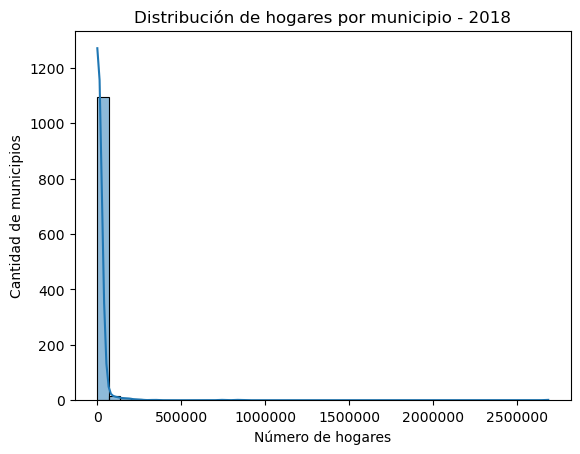

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter

# Estadísticas descriptivas
estadisticas = df_hogares_eda.groupby("anio")["hogares"].describe().round(2)

display(estadisticas)

# Distribución de hogares en 2018
sns.histplot(
    data=df_hogares_eda[df_hogares_eda["anio"] == 2020],
    x="hogares",
    bins=40,
    kde=True
)

plt.gca().xaxis.set_major_formatter(FormatStrFormatter('%d'))

plt.title("Distribución de hogares por municipio - 2018")
plt.xlabel("Número de hogares")
plt.ylabel("Cantidad de municipios")
plt.show()

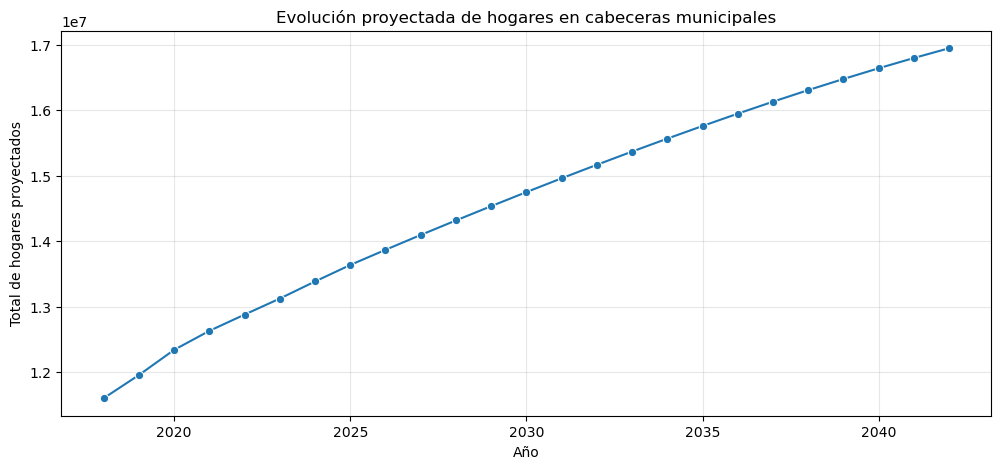

In [31]:
# Total de hogares por año
evolucion_hogares = df_hogares_eda.groupby("anio")["hogares"].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=evolucion_hogares, x="anio", y="hogares", marker="o")

plt.title("Evolución proyectada de hogares en cabeceras municipales")
plt.xlabel("Año")
plt.ylabel("Total de hogares proyectados")
plt.grid(alpha=0.3)
plt.show()

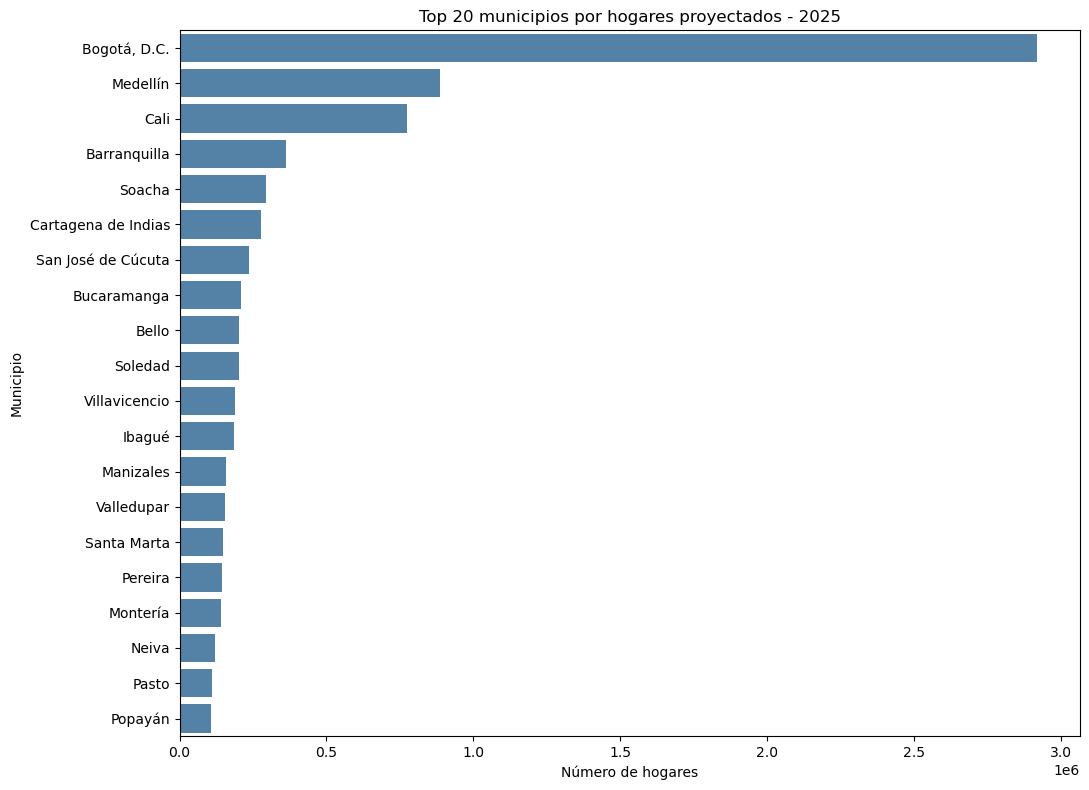

In [41]:
# Top 20 municipios en 2025
top_hogares = (
    df_hogares_eda[df_hogares_eda["anio"] == 2025]
    .nlargest(20, "hogares")
    .sort_values("hogares")
)

plt.figure(figsize=(11, 8))
sns.barplot(data=top_hogares, x="hogares", y="Nombre Municipio", color="steelblue", order=top_hogares.sort_values("hogares", ascending=False)["Nombre Municipio"])

plt.title("Top 20 municipios por hogares proyectados - 2025")
plt.xlabel("Número de hogares")
plt.ylabel("Municipio")
plt.tight_layout()
plt.show()

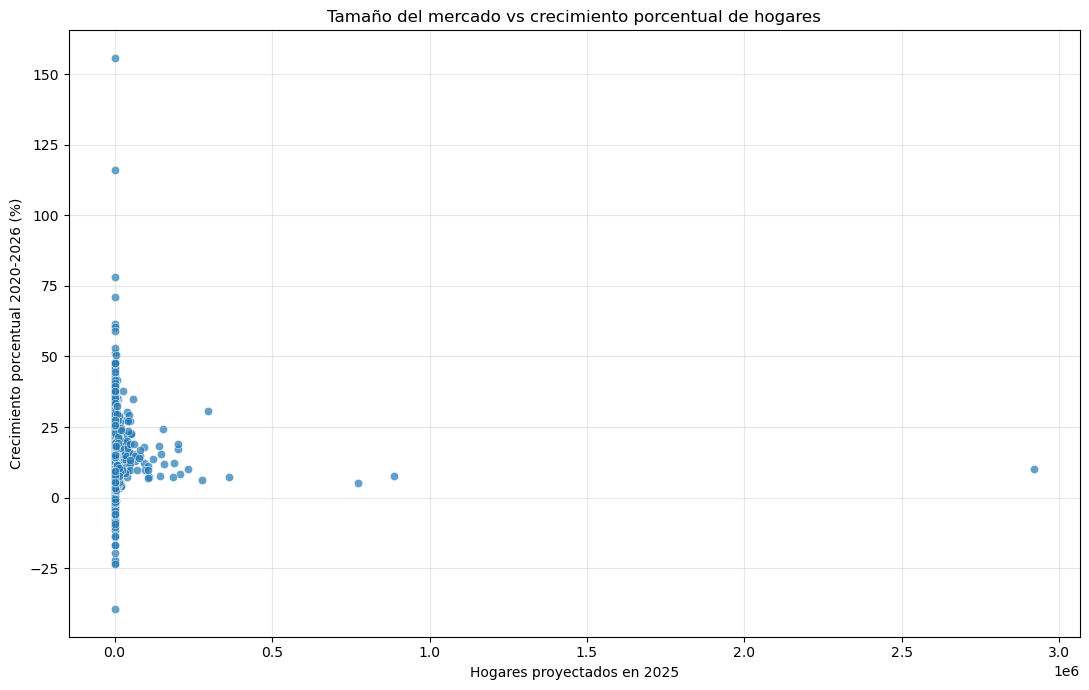

In [49]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_features_hogares.dropna(subset=["crecimiento_pct"]),
    x="2025",
    y="crecimiento_pct",
    alpha=0.7
)

plt.title("Tamaño del mercado vs crecimiento porcentual de hogares")
plt.xlabel("Hogares proyectados en 2025")
plt.ylabel("Crecimiento porcentual 2020-2026 (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Crear indicadores

In [37]:
import numpy as np
# Crear tabla de características por municipio
df_features_hogares = df_proy_hogar[
    ["divipola", "Nombre Municipio", "2018", "2020", "2025", "2026"]
].copy()

# Indicadores de crecimiento
df_features_hogares["variacion_hogares"] = df_features_hogares["2026"] - df_features_hogares["2020"]

df_features_hogares["crecimiento_pct"] = (
    df_features_hogares["variacion_hogares"] / df_features_hogares["2020"] * 100
).replace([np.inf, -np.inf], np.nan)

display(df_features_hogares.head())

,divipola,Nombre Municipio,2018,2020,2025,2026,variacion_hogares,crecimiento_pct
0,05001,Medellín,798786,833658,888029,896631,62973,7.553817
1,05002,Abejorral,2752,2945,3250,3311,366,12.427844
2,05004,Abriaquí,341,361,399,406,45,12.465374
3,05021,Alejandría,897,977,1146,1179,202,20.675537
4,05030,Amagá,4548,4883,5532,5668,785,16.076183


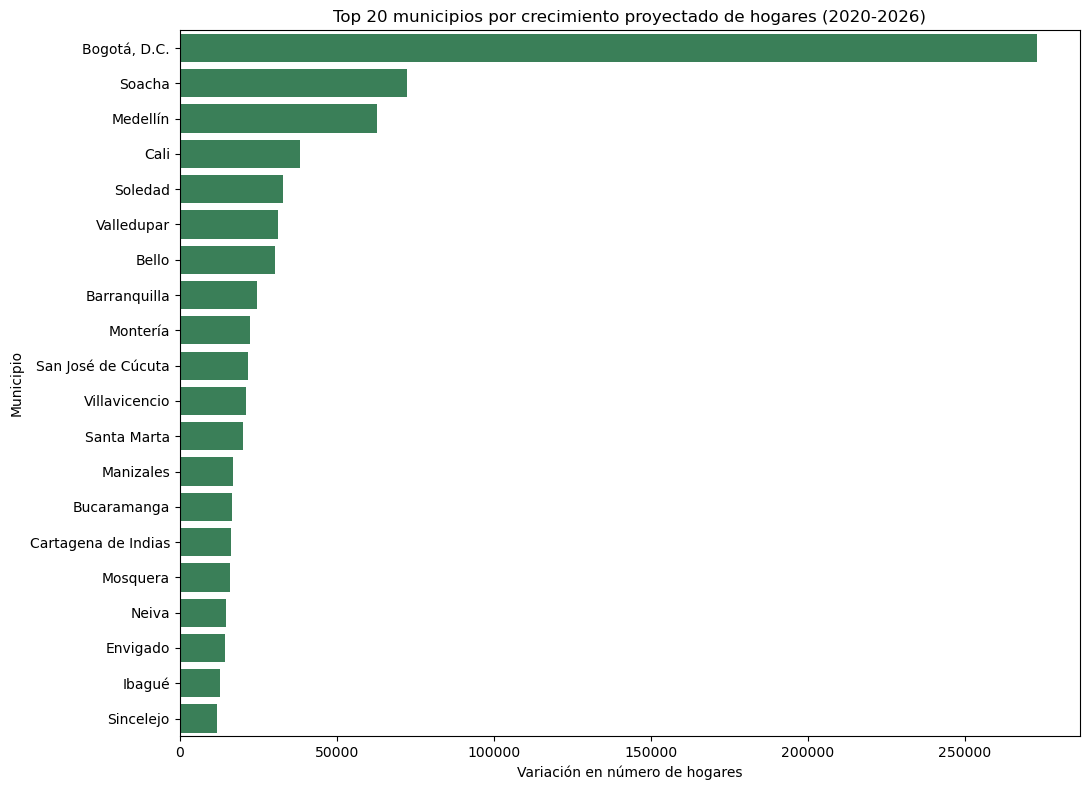

In [40]:
# Top 20 por crecimiento absoluto
top_crecimiento = df_features_hogares.nlargest(20, "variacion_hogares")

plt.figure(figsize=(11, 8))
sns.barplot(
    data=top_crecimiento.sort_values("variacion_hogares"),
    x="variacion_hogares",
    y="Nombre Municipio",
    color="seagreen",
    order=top_crecimiento.sort_values("variacion_hogares", ascending=False)["Nombre Municipio"]
)

plt.title("Top 20 municipios por crecimiento proyectado de hogares (2020-2026)")
plt.xlabel("Variación en número de hogares")
plt.ylabel("Municipio")
plt.tight_layout()
plt.show()

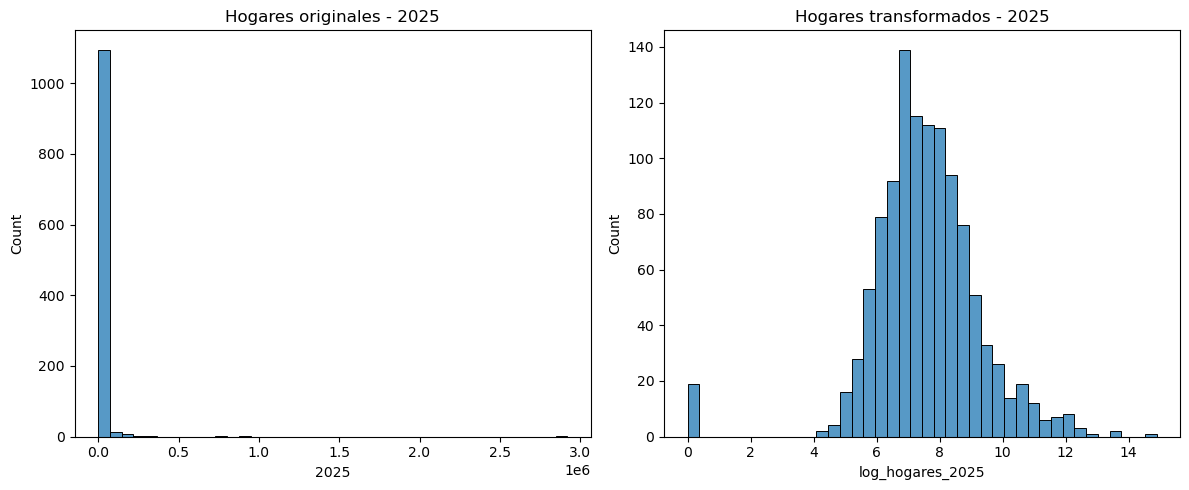

In [42]:
# Transformación logarítmica
df_features_hogares["log_hogares_2025"] = np.log1p(df_features_hogares["2025"])

# Comparar distribuciones
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_features_hogares["2025"], bins=40, ax=axes[0])
axes[0].set_title("Hogares originales - 2025")

sns.histplot(df_features_hogares["log_hogares_2025"], bins=40, ax=axes[1])
axes[1].set_title("Hogares transformados - 2025")

plt.tight_layout()
plt.show()

### clasificacion perfil

In [55]:
# Calcular puntos de referencia
mediana_tamano = df_features_hogares["2026"].median()
mediana_crecimiento = df_features_hogares["variacion_hogares"].median()

# Clasificación exploratoria
df_features_hogares["perfil"] = np.select(
    [
        (df_features_hogares["2026"] >= mediana_tamano) &
        (df_features_hogares["variacion_hogares"] >= mediana_crecimiento),

        (df_features_hogares["2026"] >= mediana_tamano) &
        (df_features_hogares["variacion_hogares"] < mediana_crecimiento),

        (df_features_hogares["2026"] < mediana_tamano) &
        (df_features_hogares["variacion_hogares"] >= mediana_crecimiento)
    ],
    [
        "Mercado grande y crecimiento alto",
        "Mercado grande y crecimiento bajo",
        "Mercado pequeño y crecimiento alto"
    ],
    default="Mercado pequeño y crecimiento bajo"
)

display(df_features_hogares["perfil"].value_counts())

perfil
Mercado grande y crecimiento alto     505
Mercado pequeño y crecimiento bajo    504
Mercado pequeño y crecimiento alto     57
Mercado grande y crecimiento bajo      57
Name: count, dtype: int64

Mercado grande y crecimiento alto
Total municipios: 505


,divipola,Nombre Municipio,2025,variacion_hogares,crecimiento_pct
0,11001,"Bogotá, D.C.",2919627,273107,10.179624
1,25754,Soacha,295077,72289,30.770704
2,05001,Medellín,888029,62973,7.553817
3,76001,Cali,773645,38245,5.166986
4,08758,Soledad,201108,33052,19.066958
...,...,...,...,...,...
500,19780,Suárez,2679,211,8.473896
501,18610,San José del Fragua,2533,211,8.971088
502,13006,Achí,2074,207,10.894737
503,17050,Aranzazu,2726,206,8.072100


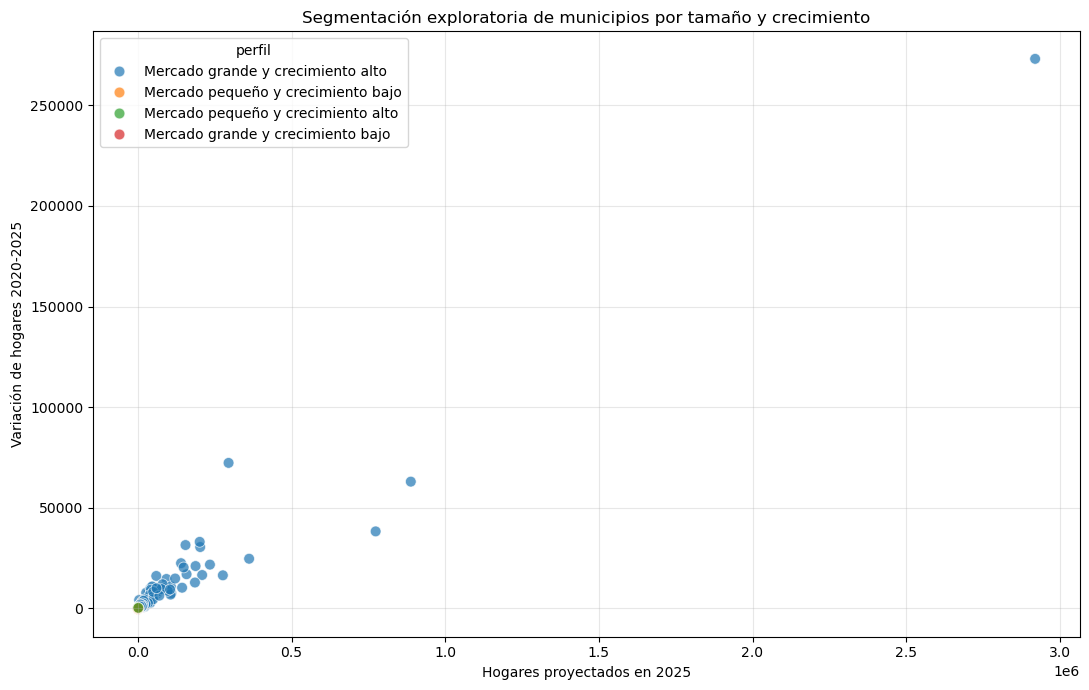

In [56]:
municipios_prioritarios = (
    df_features_hogares.loc[
        df_features_hogares["perfil"] == "Mercado grande y crecimiento alto",
        ["divipola", "Nombre Municipio", "2025", "variacion_hogares", "crecimiento_pct"]
    ]
    .sort_values("variacion_hogares", ascending=False)
    .reset_index(drop=True)
)
print("Mercado grande y crecimiento alto")
print("Total municipios:", len(municipios_prioritarios))
display(municipios_prioritarios)

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_features_hogares,
    x="2025",
    y="variacion_hogares",
    hue="perfil",
    alpha=0.7,
    s=60
)

plt.title("Segmentación exploratoria de municipios por tamaño y crecimiento")
plt.xlabel("Hogares proyectados en 2025")
plt.ylabel("Variación de hogares 2020-2025")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusiones Entendimiento

El análisis exploratorio de las proyecciones de hogares del DANE permite caracterizar la dimensión y evolución potencial de los mercados residenciales en las cabeceras municipales de Colombia. La información de 2018 a 2042 facilita identificar diferencias territoriales en el volumen de hogares y sus perspectivas de crecimiento.

Las técnicas seleccionadas permiten transformar las proyecciones originales en indicadores de tamaño y crecimiento, facilitando la comparación y clasificación preliminar de municipios según sus dinámicas residenciales. Asimismo, la segmentación exploratoria permite distinguir territorios con mercados consolidados de aquellos que presentan perspectivas de expansión.

Desde la perspectiva del negocio, esta información aporta elementos para identificar municipios con potencial de crecimiento de la demanda residencial y orientar la evaluación de nuevas oportunidades de vivienda. Sin embargo, el crecimiento proyectado de hogares no representa por sí solo demanda efectiva ni garantiza la viabilidad comercial de un proyecto.

Por tanto, los resultados son coherentes con el objetivo analítico y de negocio, dado que permiten incorporar la dinámica demográfica como una dimensión fundamental para la caracterización y priorización municipal. Su utilidad aumentará al integrarse con información de déficit habitacional, capacidad adquisitiva, transacciones inmobiliarias y condiciones de seguridad, permitiendo construir una evaluación territorial más completa para mitigar los riesgos de inversión e inmovilización de capital.